# Optimization 1: comparing neural-network optimizers

A neural network learns by repeatedly adjusting its weights to reduce the loss. The **optimizer** is the algorithm that decides how to adjust them. This notebook trains the same network several times, changing only the optimizer, so you can compare:

| Optimizer | Idea |
|---|---|
| SGD | Plain gradient descent: step downhill by a fixed learning rate |
| SGD + momentum | Remembers the previous direction, so it moves faster along consistent slopes |
| Adagrad | Gives each weight its own learning rate that shrinks as it is updated |
| RMSprop | Like Adagrad but forgets old gradients, so the rate does not shrink to zero |
| Adam | Momentum and RMSprop together (the usual default) |
| AdamW | Adam with better weight decay |
| Nadam | Adam with Nesterov momentum |

**Feasibility:** fully feasible. It trains the binary model once per optimizer, so it takes about as long as one MLP notebook times the number of optimizers. Learning rates are common defaults and are not tuned for each optimizer, so say that in your report. Run after the preprocessing notebook.

## 1. Imports

In [1]:
# %pip install tensorflow matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
import keras
from keras import layers

## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

HIDDEN_UNITS = (128, 64, 32)
DROPOUT = 0.3
BATCH_SIZE = 512
EPOCHS = 40
PATIENCE = 6           # same early stopping for every optimizer, so the comparison is fair

# name -> function that builds a fresh optimizer (learning rates are common defaults)
OPTIMIZERS = {
    "SGD":            lambda: keras.optimizers.SGD(learning_rate=0.01),
    "SGD + momentum": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "Adagrad":        lambda: keras.optimizers.Adagrad(learning_rate=0.01),
    "RMSprop":        lambda: keras.optimizers.RMSprop(learning_rate=1e-3),
    "Adam":           lambda: keras.optimizers.Adam(learning_rate=1e-3),
    "AdamW":          lambda: keras.optimizers.AdamW(learning_rate=1e-3),
    "Nadam":          lambda: keras.optimizers.Nadam(learning_rate=1e-3),
}

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Train one model per optimizer

In [4]:
def build_model(n_in):
    inputs = keras.Input(shape=(n_in,))
    x = inputs
    for units in HIDDEN_UNITS:
        x = layers.Dense(units, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(DROPOUT)(x)
    return keras.Model(inputs, layers.Dense(1, activation="sigmoid")(x))


results, histories = [], {}
for name, make_opt in OPTIMIZERS.items():
    print(f"\n=== {name}")
    keras.utils.set_random_seed(SEED)                       # same starting weights every time
    model = build_model(n_features)
    model.compile(optimizer=make_opt(), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    t0 = time.time()
    hist = model.fit(
        X_train, yb_train, validation_data=(X_val, yb_val), epochs=EPOCHS, batch_size=BATCH_SIZE,
        class_weight=cw_bin, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)])
    elapsed = time.time() - t0
    proba = model.predict(X_val, batch_size=4096, verbose=0).ravel()
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb_val, pred, labels=[0, 1]).ravel()
    histories[name] = hist.history["val_loss"]
    results.append({
        "optimizer": name,
        "epochs run": len(hist.history["loss"]),
        "best val loss": min(hist.history["val_loss"]),
        "ROC-AUC": roc_auc_score(yb_val, proba),
        "F1": f1_score(yb_val, pred),
        "recall": recall_score(yb_val, pred),
        "false_pos_rate": fp / max(fp + tn, 1),
        "train time (s)": elapsed,
    })
    print(f"epochs: {results[-1]['epochs run']}   val loss: {results[-1]['best val loss']:.4f}   F1: {results[-1]['F1']:.4f}   {elapsed:.0f}s")


=== SGD
epochs: 40   val loss: 0.1543   F1: 0.9451   57s

=== SGD + momentum
epochs: 19   val loss: 0.1332   F1: 0.9494   28s

=== Adagrad
epochs: 40   val loss: 0.1363   F1: 0.9474   56s

=== RMSprop
epochs: 22   val loss: 0.1145   F1: 0.9547   23s

=== Adam
epochs: 33   val loss: 0.1136   F1: 0.9539   35s

=== AdamW
epochs: 21   val loss: 0.1161   F1: 0.9534   30s

=== Nadam
epochs: 28   val loss: 0.1144   F1: 0.9545   45s


## 5. Results

,optimizer,epochs run,best val loss,ROC-AUC,F1,recall,false_pos_rate,train time (s)
0,RMSprop,22,0.1145,0.9915,0.9547,0.9318,0.0431,23.2775
1,Nadam,28,0.1144,0.9918,0.9545,0.9302,0.0404,44.7890
2,Adam,33,0.1136,0.9919,0.9539,0.9287,0.0394,34.7308
3,AdamW,21,0.1161,0.9915,0.9534,0.9288,0.0417,29.8984
4,SGD + momentum,19,0.1332,0.9893,0.9494,0.9266,0.0538,28.3662
5,Adagrad,40,0.1363,0.9894,0.9474,0.9200,0.0471,56.4492
6,SGD,40,0.1543,0.9866,0.9451,0.9219,0.0618,57.3427


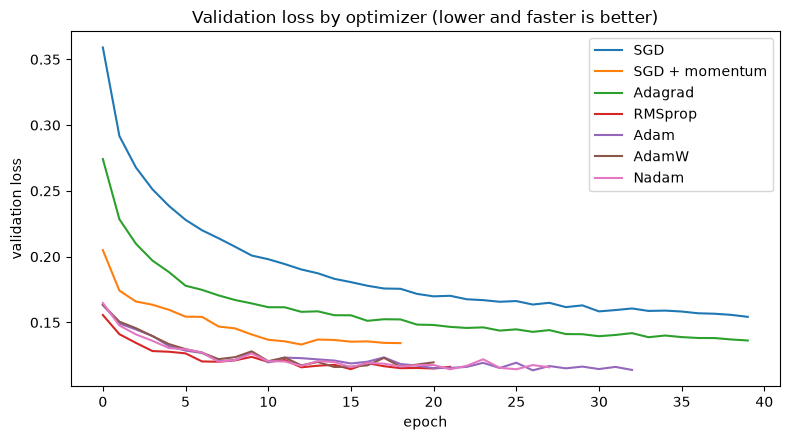

best optimizer by F1: RMSprop


In [5]:
res = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
display(res.round(4))

plt.figure(figsize=(8, 4.5))
for name, vl in histories.items():
    plt.plot(vl, label=name)
plt.xlabel("epoch"); plt.ylabel("validation loss")
plt.title("Validation loss by optimizer (lower and faster is better)")
plt.legend(); plt.tight_layout(); plt.show()

best = res.iloc[0]["optimizer"]
print(f"best optimizer by F1: {best}")

## 6. Save the comparison

The table is saved as `optimizer_comparison.csv`. It uses a different name from the model summaries, so it does not get mixed into the model comparison table.

In [6]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)
res.to_csv(mdir / "optimizer_comparison.csv", index=False)
print("saved", mdir / "optimizer_comparison.csv")

saved models\optimizer_comparison.csv
